# Blood Donation Prediction — PRCP-1011

**Goal.** A mobile blood-donation vehicle in Taiwan visits universities and runs blood drives. We want to predict **whether a donor will donate again at the next visit (March 2007)** using only a handful of attributes, so the Blood Transfusion Service Center can focus reminders and outreach on donors who are likely to respond.

**Deliverables in this single notebook**

| # | Section |
|---|---------|
| 1 | Data analysis report (Task 1) |
| 2 | Predictive modelling (Task 2) |
| 3 | Model comparison report |
| 4 | Report on challenges faced |

**Evaluation choice.** The classes are imbalanced (roughly 1 donor in 4 donates again), so plain accuracy is misleading — a model that always says "won't donate" already scores about 76%. The primary metrics here are **ROC-AUC** (ranking quality) and **log loss** (quality of the predicted probabilities, which is what an outreach team would use to prioritise donors). F1, precision and recall are reported at a tuned decision threshold.

In [1]:
import warnings, json
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import (train_test_split, RepeatedStratifiedKFold,
                                     cross_validate, cross_val_predict, GridSearchCV,
                                     StratifiedKFold)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                              AdaBoostClassifier)
from sklearn.metrics import (roc_auc_score, log_loss, accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix, roc_curve,
                             precision_recall_curve, average_precision_score,
                             brier_score_loss)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.width", 140)

In [2]:
# Update this path if the CSV lives elsewhere (it is inside Data/ in the project zip)
DATA_PATH = "Data/Warm_Up_Predict_Blood_Donations_-_Traning_Data.csv"
try:
    raw = pd.read_csv(DATA_PATH)
except FileNotFoundError:
    raw = pd.read_csv("Warm_Up_Predict_Blood_Donations_-_Traning_Data.csv")

raw.head()

,Unnamed: 0,Months since Last Donation,Number of Donations,Total Volume Donated (c.c.),Months since First Donation,Made Donation in March 2007
0,619,2,50,12500,98,1
1,664,0,13,3250,28,1
2,441,1,16,4000,35,1
3,160,2,20,5000,45,1
4,358,1,24,6000,77,0


---
# 1. Data Analysis Report (Task 1)

## 1.1 Dataset overview

In [3]:
print("Shape:", raw.shape)
print()
raw.info()

Shape: (576, 6)

<class 'pandas.DataFrame'>
RangeIndex: 576 entries, 0 to 575
Data columns (total 6 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   Unnamed: 0                   576 non-null    int64
 1   Months since Last Donation   576 non-null    int64
 2   Number of Donations          576 non-null    int64
 3   Total Volume Donated (c.c.)  576 non-null    int64
 4   Months since First Donation  576 non-null    int64
 5   Made Donation in March 2007  576 non-null    int64
dtypes: int64(6)
memory usage: 27.1 KB


In [4]:
# Short, code-friendly column names (original names are kept in the mapping below)
rename_map = {
    "Unnamed: 0": "donor_id",
    "Months since Last Donation": "recency",
    "Number of Donations": "frequency",
    "Total Volume Donated (c.c.)": "volume_cc",
    "Months since First Donation": "time",
    "Made Donation in March 2007": "target",
}
df = raw.rename(columns=rename_map)
pd.DataFrame({"original name": rename_map.keys(), "short name": rename_map.values()})

,original name,short name
0,Unnamed: 0,donor_id
1,Months since Last Donation,recency
2,Number of Donations,frequency
3,Total Volume Donated (c.c.),volume_cc
4,Months since First Donation,time
5,Made Donation in March 2007,target


The dataset is the classic **RFMT** layout from direct marketing:

* **recency** – months since the last donation (R)
* **frequency** – total number of donations (F)
* **volume_cc** – total blood donated in c.c. (M, "monetary")
* **time** – months since the first donation (T)
* **target** – donated in March 2007 (1) or not (0)
* `donor_id` (the *Unnamed: 0* column) is just a row identifier and is ignored for modelling, as the brief says.

## 1.2 Data quality checks

In [5]:
print("Fully duplicated rows (incl. id):", df.duplicated().sum())
print("Rows identical on all *feature* columns (ignoring id):",
      df.drop(columns="donor_id").duplicated().sum())
print("Is donor_id unique?", df["donor_id"].is_unique)

quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "unique values": df.nunique(),
    "min": df.min(),
    "max": df.max(),
})
quality

Fully duplicated rows (incl. id): 0
Rows identical on all *feature* columns (ignoring id): 153
Is donor_id unique? True


,dtype,missing,unique values,min,max
donor_id,int64,0,576,0,747
recency,int64,0,29,0,74
frequency,int64,0,29,1,50
volume_cc,int64,0,29,250,12500
time,int64,0,75,2,98
target,int64,0,2,0,1


**Observations**

* No missing values and every column is numeric, so no imputation or encoding is needed.
* `donor_id` is unique; there are no fully duplicated records.
* A number of rows share identical feature values, but they have different IDs. They are **different donors who look alike** (for example, people who gave once, recently). They are legitimate observations and are *not* removed — dropping them would erase real information about how common these donor profiles are.

## 1.3 Logical-consistency checks

In [6]:
checks = {
    "volume_cc == 250 x frequency (every row)": bool((df["volume_cc"] == 250 * df["frequency"]).all()),
    "time >= recency (first donation is never after the last)": bool((df["time"] >= df["recency"]).all()),
    "frequency >= 1": bool((df["frequency"] >= 1).all()),
    "recency >= 0": bool((df["recency"] >= 0).all()),
    "target is binary": set(df["target"].unique()) <= {0, 1},
}
pd.Series(checks, name="passes?").to_frame()

,passes?
volume_cc == 250 x frequency (every row),True
time >= recency (first donation is never after the last),True
frequency >= 1,True
recency >= 0,True
target is binary,True


**Key finding — `volume_cc` is redundant.** Every donation in this centre is exactly 250 c.c., so `volume_cc = 250 × frequency` for all rows (correlation of exactly 1.0). It carries no extra information and creates perfect multicollinearity, which destabilises linear-model coefficients. It is therefore **dropped** before modelling.

## 1.4 Descriptive statistics

In [7]:
feat_cols = ["recency", "frequency", "volume_cc", "time"]
summary = df[feat_cols].describe().T
summary["skew"] = df[feat_cols].skew()
summary["kurtosis"] = df[feat_cols].kurt()
summary.round(2)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
recency,576.0,9.44,8.18,0.0,2.0,7.0,14.00,74.0,2.07,11.42
frequency,576.0,5.43,5.74,1.0,2.0,4.0,7.00,50.0,3.50,18.94
volume_cc,576.0,1356.77,1435.00,250.0,500.0,1000.0,1750.00,12500.0,3.50,18.94
time,576.0,34.05,24.23,2.0,16.0,28.0,49.25,98.0,0.77,-0.19


## 1.5 Target distribution

                    count  percent
target                            
0 - did not donate    438     76.0
1 - donated           138     24.0
Majority-class baseline accuracy: 0.760


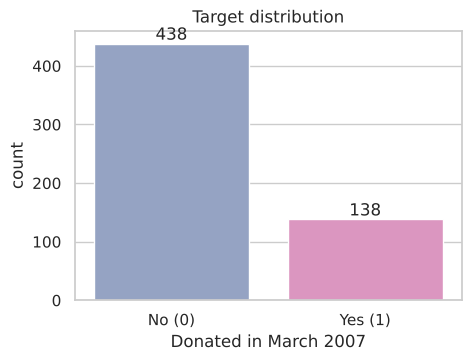

In [8]:
counts = df["target"].value_counts().sort_index()
pct = df["target"].value_counts(normalize=True).sort_index() * 100
print(pd.DataFrame({"count": counts, "percent": pct.round(1)}).rename(index={0: "0 - did not donate", 1: "1 - donated"}))

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(x="target", data=df, palette=["#8da0cb", "#e78ac3"], ax=ax)
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
ax.set_xticklabels(["No (0)", "Yes (1)"]); ax.set_xlabel("Donated in March 2007")
ax.set_title("Target distribution"); plt.show()

majority_baseline = counts.max() / counts.sum()
print(f"Majority-class baseline accuracy: {majority_baseline:.3f}")

The target is **imbalanced (~76% / 24%)**. A trivial "nobody will donate" classifier is already ~76% accurate, so accuracy alone cannot be used to judge models. This drives the metric choices (ROC-AUC, log loss, F1, recall) and the use of **stratified** splits throughout.

## 1.6 Univariate analysis

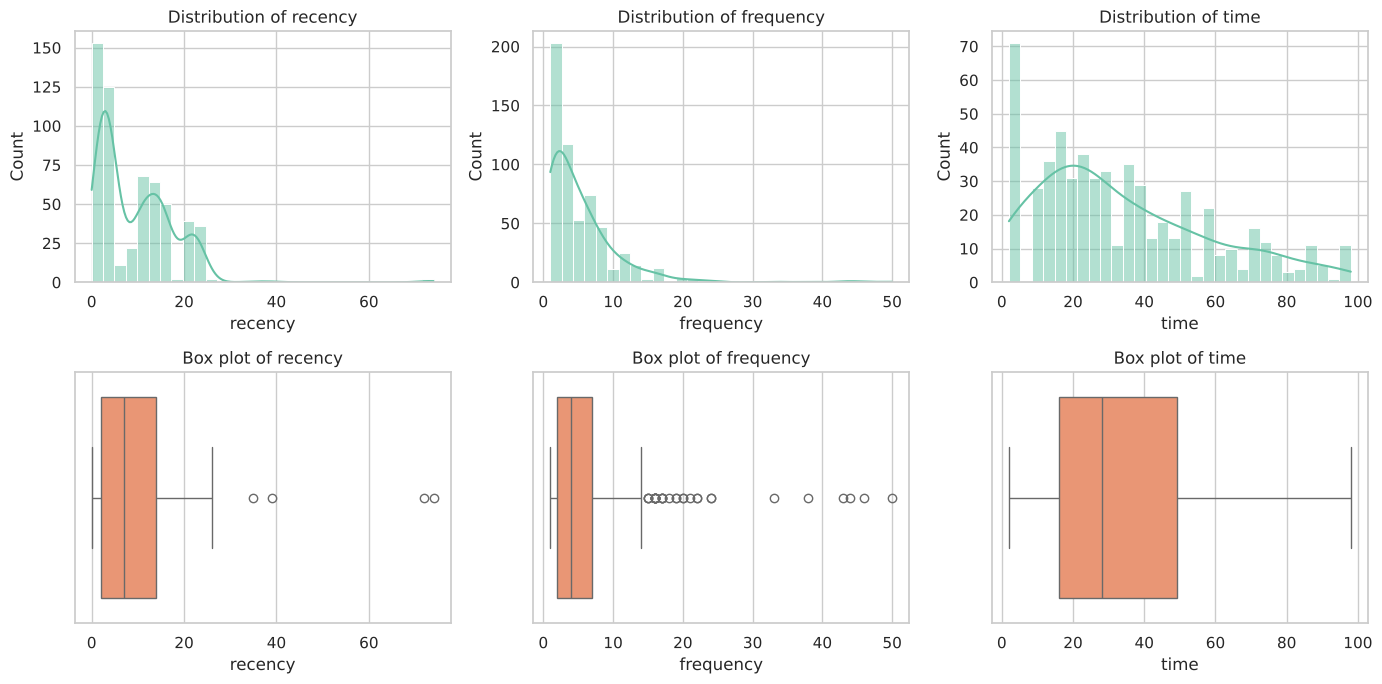

In [9]:
uni_cols = ["recency", "frequency", "time"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for i, c in enumerate(uni_cols):
    sns.histplot(df[c], bins=30, kde=True, ax=axes[0, i], color="#66c2a5")
    axes[0, i].set_title(f"Distribution of {c}")
    sns.boxplot(x=df[c], ax=axes[1, i], color="#fc8d62")
    axes[1, i].set_title(f"Box plot of {c}")
plt.tight_layout(); plt.show()

In [10]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((s < lo) | (s > hi)).sum(), lo, hi

rows = []
for c in uni_cols:
    n, lo, hi = iqr_outliers(df[c])
    rows.append({"feature": c, "IQR outliers": n, "% of rows": round(100 * n / len(df), 1),
                 "lower fence": round(lo, 1), "upper fence": round(hi, 1), "skew": round(df[c].skew(), 2)})
pd.DataFrame(rows)

,feature,IQR outliers,% of rows,lower fence,upper fence,skew
0,recency,4,0.7,-16.0,32.0,2.07
1,frequency,31,5.4,-5.5,14.5,3.50
2,time,0,0.0,-33.9,99.1,0.77


**Observations**

* `recency` and `frequency` are strongly **right-skewed**: most donors gave recently and only a few times, but a small group are very loyal repeat donors (up to 50 donations).
* The box plots flag a number of high values in `frequency`. These are **genuine heavy donors, not errors** — and they are exactly the people most likely to donate again — so they are kept. Instead of deleting them, the skew is handled with a log transform and with scale-robust / tree-based models (see Section 2).
* `time` (account age) is closer to symmetric with a bump of long-standing donors.

## 1.7 Relationship with the target (bivariate analysis)

       recency        frequency          time       
          mean median      mean median   mean median
target                                              
0        10.64   11.0      4.72    3.0  34.32   27.0
1         5.64    4.0      7.68    6.0  33.20   28.0


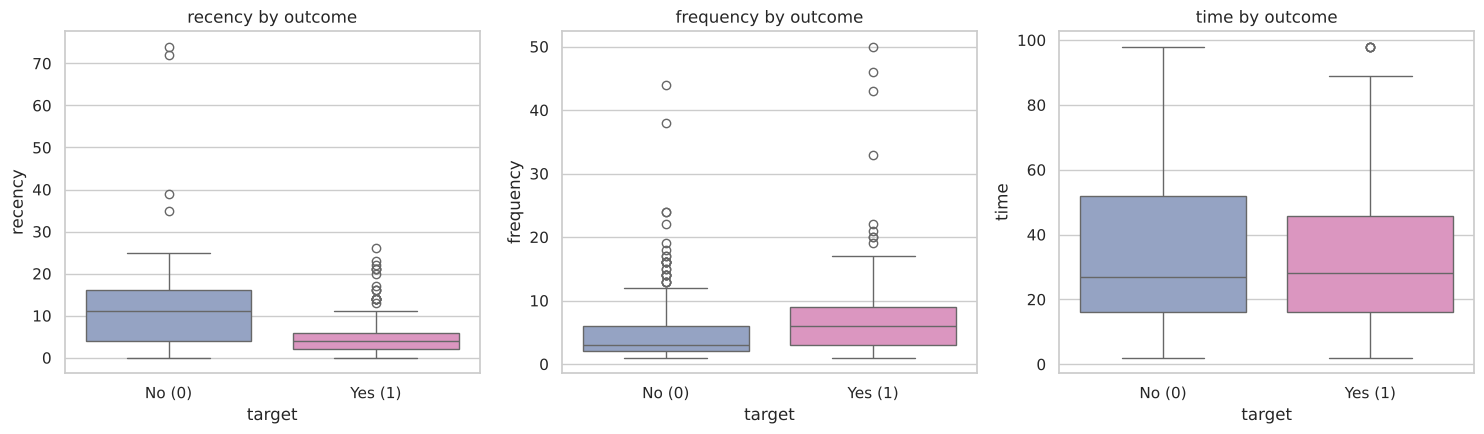

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, c in zip(axes, uni_cols):
    sns.boxplot(x="target", y=c, data=df, palette=["#8da0cb", "#e78ac3"], ax=ax)
    ax.set_xticklabels(["No (0)", "Yes (1)"]); ax.set_title(f"{c} by outcome")
plt.tight_layout(); plt.show()

print(df.groupby("target")[uni_cols].agg(["mean", "median"]).round(2))

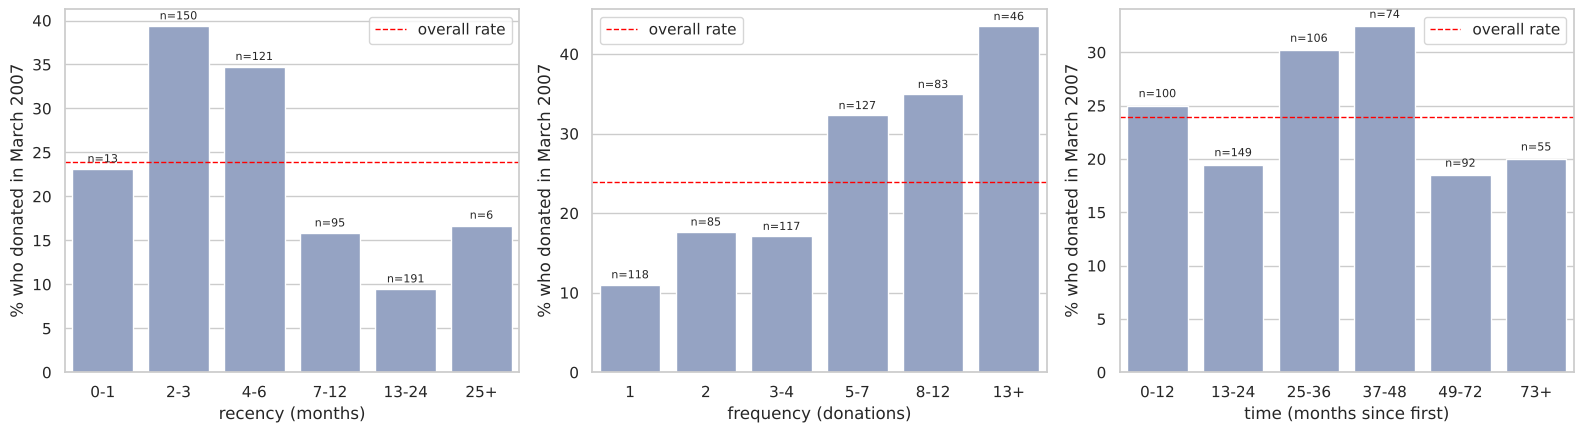

In [12]:
# Donation rate by bucket - makes the *shape* of each relationship visible
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

rec_bins = pd.cut(df["recency"], [-1, 1, 3, 6, 12, 24, 100], labels=["0-1", "2-3", "4-6", "7-12", "13-24", "25+"])
freq_bins = pd.cut(df["frequency"], [0, 1, 2, 4, 7, 12, 100], labels=["1", "2", "3-4", "5-7", "8-12", "13+"])
time_bins = pd.cut(df["time"], [-1, 12, 24, 36, 48, 72, 120], labels=["0-12", "13-24", "25-36", "37-48", "49-72", "73+"])

for ax, b, name in zip(axes, [rec_bins, freq_bins, time_bins], ["recency (months)", "frequency (donations)", "time (months since first)"]):
    g = df.groupby(b, observed=True)["target"].agg(["mean", "size"])
    sns.barplot(x=g.index.astype(str), y=g["mean"] * 100, ax=ax, color="#8da0cb")
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(i, m * 100 + 0.8, f"n={n}", ha="center", fontsize=8)
    ax.axhline(df["target"].mean() * 100, color="red", ls="--", lw=1, label="overall rate")
    ax.set_ylabel("% who donated in March 2007"); ax.set_xlabel(name); ax.legend()
plt.tight_layout(); plt.show()

**Observations**

* **Recency is the strongest signal, but not a straight line.** Donors whose last donation was 2–6 months ago return most often (about 35–39%); the rate then drops to about 16% at 7–12 months and about 9% at 13–24 months. The two extreme buckets (0–1 months, n=13; 25+ months, n=6) are far too small to read anything into. A plausible explanation for the weaker 0–1 month group is that donors must wait between donations, but that is a hypothesis the data cannot confirm.
* **Frequency** rises roughly steadily: one-time donors return about 11% of the time versus about 43% for donors with 13+ donations.
* **Time since first donation** is only weakly related to the outcome on its own (the rate wobbles between about 18% and 32% with no clear trend, and the Mann-Whitney test below finds no difference). It may still matter in combination with the other two (a donor with 10 donations over 12 months behaves differently from one with 10 over 8 years), which motivates the engineered features in Section 2.

## 1.8 Correlation and multicollinearity

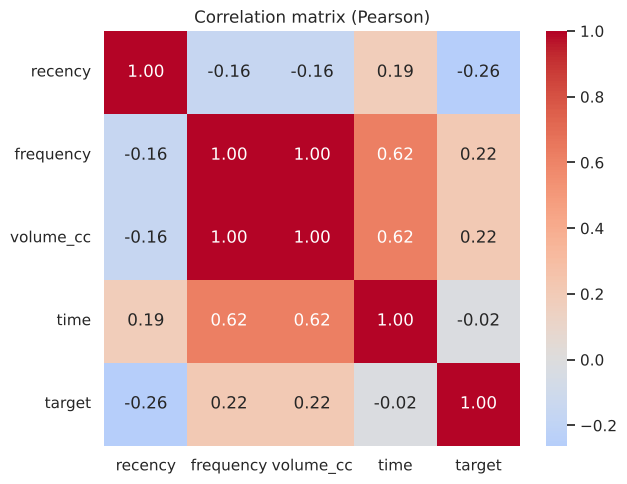

In [13]:
fig, ax = plt.subplots(figsize=(6.5, 5))
corr = df.drop(columns="donor_id").corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation matrix (Pearson)"); plt.tight_layout(); plt.show()

In [14]:
def vif_table(X):
    X = X.astype(float); out = {}
    for c in X.columns:
        y = X[c].values
        others = np.column_stack([np.ones(len(X)), X.drop(columns=c).values])
        beta, *_ = np.linalg.lstsq(others, y, rcond=None)
        resid = y - others @ beta
        r2 = 1 - resid.var() / y.var()
        out[c] = np.inf if r2 > 1 - 1e-10 else 1 / (1 - r2)
    return pd.Series(out, name="VIF")

print("VIF with volume_cc included:"); print(vif_table(df[feat_cols]).round(2).to_string())
print()
print("VIF after dropping volume_cc:"); print(vif_table(df[uni_cols]).round(2).to_string())

VIF with volume_cc included:
recency      1.19
frequency     inf
volume_cc     inf
time         1.89

VIF after dropping volume_cc:
recency      1.19
frequency    1.87
time         1.89


`volume_cc` and `frequency` are perfectly correlated (r = 1.00, VIF = ∞). After dropping `volume_cc`, all VIFs fall to a safe level, so the remaining three raw features can be used together.

## 1.9 Statistical tests

In [15]:
# Mann-Whitney U (non-parametric, appropriate for the skewed features) donors vs non-donors
rows = []
for c in uni_cols:
    a, b = df.loc[df.target == 1, c], df.loc[df.target == 0, c]
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    rows.append({"feature": c, "median (donated)": a.median(), "median (not donated)": b.median(),
                 "U statistic": u, "p-value": p, "significant at 0.05": p < 0.05})
pd.DataFrame(rows)

,feature,median (donated),median (not donated),U statistic,p-value,significant at 0.05
0,recency,4.0,11.0,18851.5,1.410830e-11,True
1,frequency,6.0,3.0,39922.0,9.785823e-09,True
2,time,28.0,27.0,29902.5,8.514474e-01,False


## 1.10 Summary of the data analysis

| Topic | Finding | Action |
|---|---|---|
| Size / quality | 576 donors, no missing values, all numeric | None needed |
| Redundancy | `volume_cc = 250 × frequency` exactly | Drop `volume_cc` |
| Identifier | `donor_id` has no predictive meaning | Drop |
| Class balance | ~24% positive | Stratified splits, ROC-AUC / log loss / F1 |
| Skew & outliers | `recency` and `frequency` right-skewed; high values are real loyal donors | Keep; log-transform for linear models |
| Signal | Higher frequency → more likely to donate; recency matters most (best at 2–6 months, falling after a year); `time` is weak alone | Engineer ratio features |

---
# 2. Predictive Modelling (Task 2)

## 2.1 Feature engineering

Only the three informative raw attributes are used (`recency`, `frequency`, `time`) — this satisfies the brief's "limited number of attributes" and keeps the model cheap to run in production. Four engineered features add behavioural context:

| Feature | Formula | Why |
|---|---|---|
| `donation_rate` | `frequency / (time + 1)` | Donations per month of membership — separates intense from casual donors |
| `tenure_gap` | `time - recency` | Months between first and last donation (the active span) |
| `log_frequency` | `log(1 + frequency)` | Tames the right skew for linear / distance-based models |
| `log_recency` | `log(1 + recency)` | Same, for recency |

Feature engineering is wrapped in a `FunctionTransformer` **inside the pipeline**, so the saved model accepts the three raw columns directly and there is no train/serve mismatch.

In [16]:
# The feature code is written to a small module so the saved model can be loaded
# in any other process (pickle stores functions by reference, not by value).
import os, sys
feature_module = '''import numpy as np
import pandas as pd

RAW_FEATURES = ["recency", "frequency", "time"]

def add_features(X):
    X = pd.DataFrame(X, columns=RAW_FEATURES).copy()
    X["donation_rate"] = X["frequency"] / (X["time"] + 1)   # donations per month of membership
    X["tenure_gap"] = X["time"] - X["recency"]               # months between first and last donation
    X["log_frequency"] = np.log1p(X["frequency"])
    X["log_recency"] = np.log1p(X["recency"])
    return X
'''
with open("donor_features.py", "w") as f:
    f.write(feature_module)
sys.path.insert(0, os.getcwd())
from donor_features import RAW_FEATURES, add_features

feature_step = FunctionTransformer(add_features, validate=False)

X = df[RAW_FEATURES]
y = df["target"]
add_features(X).describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
recency,576.0,9.44,8.18,0.00,2.00,7.00,14.00,74.00
frequency,576.0,5.43,5.74,1.00,2.00,4.00,7.00,50.00
time,576.0,34.05,24.23,2.00,16.00,28.00,49.25,98.00
donation_rate,576.0,0.18,0.12,0.01,0.08,0.15,0.24,0.80
tenure_gap,576.0,24.61,24.08,0.00,0.75,19.00,40.25,96.00
log_frequency,576.0,1.60,0.69,0.69,1.10,1.61,2.08,3.93
log_recency,576.0,2.05,0.80,0.00,1.10,2.08,2.71,4.32


## 2.2 Train / test split

A stratified 80/20 split keeps the 24% positive rate in both parts. The **test set is held back and used once**, at the very end. All model selection and tuning use cross-validation on the training portion only, so the test score is an honest estimate of future performance.

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)

print(f"Train: {X_train.shape}, positive rate = {y_train.mean():.3f}")
print(f"Test : {X_test.shape}, positive rate = {y_test.mean():.3f}")

Train: (460, 3), positive rate = 0.239
Test : (116, 3), positive rate = 0.241


## 2.3 Baseline and multi-model comparison

Nine algorithms from different families are compared with **5-fold stratified cross-validation repeated 3 times** (15 fits each). With only ~460 training rows, repetition matters: a single 5-fold split is noisy, and differences of 1–2 AUC points are within the noise.

Distance-based and linear models get a `StandardScaler`; tree-based models do not need one.

In [18]:
def make_pipe(model, scale=False, engineered=True):
    steps = []
    if engineered:
        steps.append(("features", feature_step))
    else:
        steps.append(("select", FunctionTransformer(lambda d: pd.DataFrame(d, columns=RAW_FEATURES), validate=False)))
    if scale:
        steps.append(("scale", StandardScaler()))
    steps.append(("model", model))
    return Pipeline(steps)

candidates = {
    "Dummy (prior)":            make_pipe(DummyClassifier(strategy="prior")),
    "Logistic Regression":      make_pipe(LogisticRegression(max_iter=2000, random_state=SEED), scale=True),
    "Logistic Reg. (balanced)": make_pipe(LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED), scale=True),
    "KNN (k=15)":               make_pipe(KNeighborsClassifier(n_neighbors=15), scale=True),
    "SVM (RBF)":                make_pipe(SVC(probability=True, random_state=SEED), scale=True),
    "Gaussian Naive Bayes":     make_pipe(GaussianNB()),
    "Decision Tree (depth 3)":  make_pipe(DecisionTreeClassifier(max_depth=3, random_state=SEED)),
    "Random Forest":            make_pipe(RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=SEED, n_jobs=-1)),
    "Gradient Boosting":        make_pipe(GradientBoostingClassifier(n_estimators=100, max_depth=2, learning_rate=0.05, random_state=SEED)),
    "AdaBoost":                 make_pipe(AdaBoostClassifier(random_state=SEED)),
}

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
scoring = {"roc_auc": "roc_auc", "log_loss": "neg_log_loss", "accuracy": "accuracy",
           "precision": "precision", "recall": "recall", "f1": "f1"}

def compare(models):
    rows = []
    for name, pipe in models.items():
        r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
        rows.append({
            "model": name,
            "ROC-AUC": r["test_roc_auc"].mean(), "AUC std": r["test_roc_auc"].std(),
            "log loss": -r["test_log_loss"].mean(),
            "accuracy": r["test_accuracy"].mean(),
            "precision": r["test_precision"].mean(),
            "recall": r["test_recall"].mean(),
            "F1": r["test_f1"].mean(),
        })
    return pd.DataFrame(rows).set_index("model").sort_values("ROC-AUC", ascending=False)

cv_results = compare(candidates)
cv_results.round(3)

,ROC-AUC,AUC std,log loss,accuracy,precision,recall,F1
model,,,,,,,
Logistic Regression,0.769,0.042,0.463,0.787,0.619,0.306,0.399
Logistic Reg. (balanced),0.767,0.042,0.573,0.686,0.410,0.706,0.518
Gaussian Naive Bayes,0.759,0.055,0.753,0.760,0.502,0.558,0.525
Gradient Boosting,0.745,0.052,0.485,0.790,0.620,0.342,0.433
AdaBoost,0.743,0.053,0.559,0.783,0.530,0.385,0.441
KNN (k=15),0.741,0.055,0.639,0.796,0.620,0.400,0.482
Random Forest,0.728,0.048,0.525,0.796,0.610,0.403,0.482
Decision Tree (depth 3),0.719,0.052,0.866,0.772,0.519,0.467,0.480
SVM (RBF),0.710,0.056,0.492,0.789,0.621,0.327,0.423


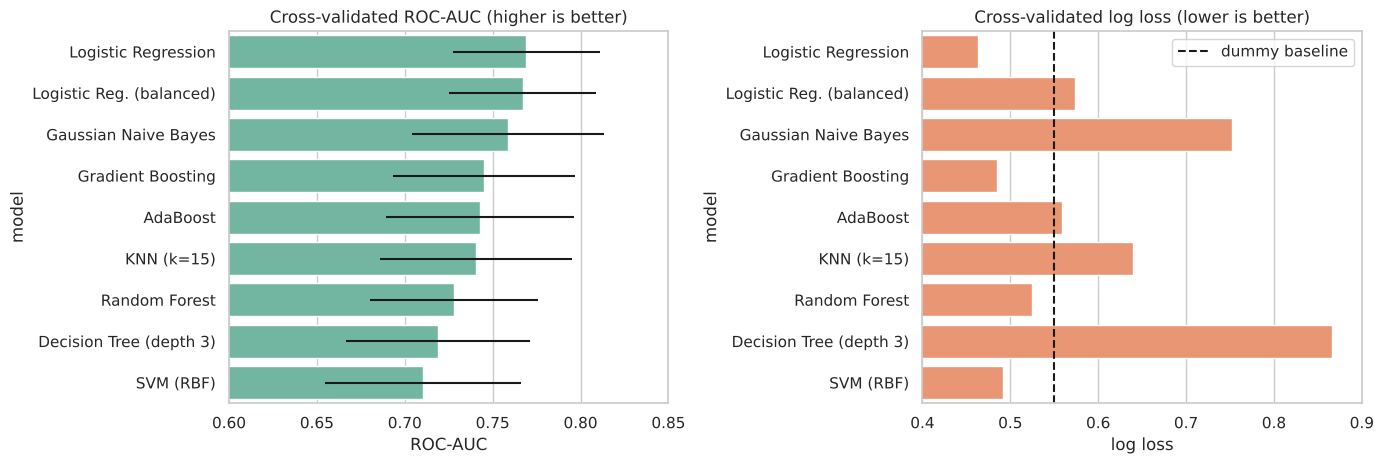

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
order = cv_results.drop("Dummy (prior)").index
sns.barplot(y=order, x=cv_results.loc[order, "ROC-AUC"], xerr=cv_results.loc[order, "AUC std"], ax=axes[0], color="#66c2a5")
axes[0].set_xlim(0.6, 0.85); axes[0].set_title("Cross-validated ROC-AUC (higher is better)")
sns.barplot(y=order, x=cv_results.loc[order, "log loss"], ax=axes[1], color="#fc8d62")
axes[1].axvline(cv_results.loc["Dummy (prior)", "log loss"], color="k", ls="--", label="dummy baseline")
axes[1].set_xlim(0.4, 0.9); axes[1].legend(); axes[1].set_title("Cross-validated log loss (lower is better)")
plt.tight_layout(); plt.show()

### Does feature engineering help?  (raw 3 features vs engineered 7)

In [20]:
ablation_models = {
    "Logistic Regression":  LogisticRegression(max_iter=2000, random_state=SEED),
    "Gradient Boosting":    GradientBoostingClassifier(n_estimators=100, max_depth=2, learning_rate=0.05, random_state=SEED),
    "Random Forest":        RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=SEED, n_jobs=-1),
}
rows = []
for name, m in ablation_models.items():
    for eng in (False, True):
        scale = name == "Logistic Regression"
        r = cross_validate(make_pipe(m, scale=scale, engineered=eng), X_train, y_train, cv=cv,
                           scoring={"auc": "roc_auc", "ll": "neg_log_loss"}, n_jobs=-1)
        rows.append({"model": name, "features": "engineered (7)" if eng else "raw (3)",
                     "ROC-AUC": r["test_auc"].mean(), "log loss": -r["test_ll"].mean()})
pd.DataFrame(rows).pivot(index="model", columns="features", values=["ROC-AUC", "log loss"]).round(3)

ROC-AUC               log loss        
features            engineered (7) raw (3) engineered (7) raw (3)
model                                                            
Gradient Boosting            0.745   0.726          0.485   0.493
Logistic Regression          0.769   0.762          0.463   0.482
Random Forest                0.728   0.731          0.525   0.493

## 2.4 Hyper-parameter tuning

The most promising families (a regularised linear model, and the two tree ensembles) are tuned with `GridSearchCV`, optimising **log loss** on the training data only. Small grids and shallow trees are deliberate: with ~460 rows, large grids over-fit the cross-validation folds.

In [21]:
grids = {
    "Logistic Regression": (
        make_pipe(LogisticRegression(max_iter=2000, random_state=SEED), scale=True),
        {"model__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]}),
    "Random Forest": (
        make_pipe(RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)),
        {"model__max_depth": [3, 5, None], "model__min_samples_leaf": [5, 10, 20], "model__max_features": ["sqrt", None]}),
    "Gradient Boosting": (
        make_pipe(GradientBoostingClassifier(random_state=SEED)),
        {"model__n_estimators": [50, 100, 200], "model__max_depth": [1, 2, 3],
         "model__learning_rate": [0.02, 0.05, 0.1], "model__subsample": [0.8, 1.0]}),
}

tune_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED)
tuned, rows = {}, []
for name, (pipe, grid) in grids.items():
    gs = GridSearchCV(pipe, grid, scoring="neg_log_loss", cv=tune_cv, n_jobs=-1, refit=True)
    gs.fit(X_train, y_train)
    tuned[name] = gs.best_estimator_
    rows.append({"model": name, "best CV log loss": -gs.best_score_, "best params": gs.best_params_})
pd.DataFrame(rows).set_index("model")

,best CV log loss,best params
model,,
Logistic Regression,0.462673,{'model__C': 0.3}
Random Forest,0.475511,"{'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 20}"
Gradient Boosting,0.474954,"{'model__learning_rate': 0.05, 'model__max_depth': 1, 'model__n_estimators': 200, 'model__subsample': 0.8}"


In [22]:
tuned_cv = compare(tuned)
tuned_cv.round(3)

,ROC-AUC,AUC std,log loss,accuracy,precision,recall,F1
model,,,,,,,
Logistic Regression,0.769,0.043,0.463,0.784,0.619,0.267,0.364
Gradient Boosting,0.752,0.050,0.477,0.789,0.615,0.339,0.431
Random Forest,0.748,0.042,0.475,0.791,0.628,0.336,0.433


## 2.5 Choosing a decision threshold

The default 0.5 cut-off is poor when only ~24% of donors are positive: the model rarely reaches 50% confidence, so recall is low (about 0.27 for the tuned logistic regression in cross-validation). The threshold is therefore chosen from **out-of-fold predictions on the training set** (never from the test set) to maximise F1. In practice, the outreach team could move it up or down depending on how many donors it can afford to contact.

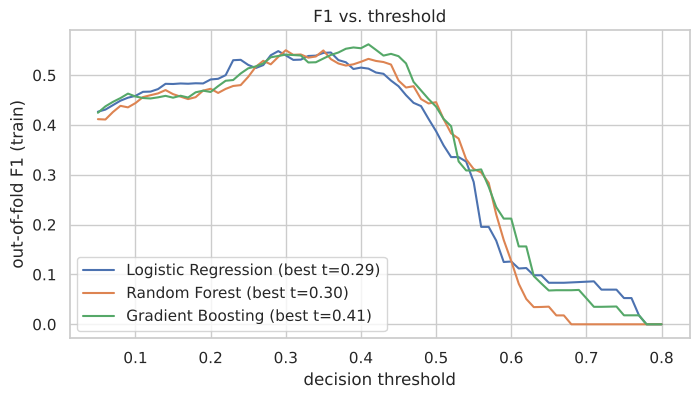

{'Logistic Regression': 0.29, 'Random Forest': 0.3, 'Gradient Boosting': 0.41}

In [23]:
def best_f1_threshold(pipe, X_tr, y_tr):
    oof = cross_val_predict(pipe, X_tr, y_tr, cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
                            method="predict_proba")[:, 1]
    ths = np.linspace(0.05, 0.8, 76)
    f1s = [f1_score(y_tr, oof >= t) for t in ths]
    return ths[int(np.argmax(f1s))], ths, f1s

thresholds = {}
fig, ax = plt.subplots(figsize=(8, 4))
for name, pipe in tuned.items():
    t, ths, f1s = best_f1_threshold(pipe, X_train, y_train)
    thresholds[name] = float(t)
    ax.plot(ths, f1s, label=f"{name} (best t={t:.2f})")
ax.set_xlabel("decision threshold"); ax.set_ylabel("out-of-fold F1 (train)")
ax.set_title("F1 vs. threshold"); ax.legend(); plt.show()
thresholds

## 2.6 Final evaluation on the untouched test set

Each tuned model is fitted on the full training set and scored once on the 116 held-out donors.

In [24]:
def evaluate(pipe, name, threshold):
    pipe.fit(X_train, y_train)
    p = pipe.predict_proba(X_test)[:, 1]
    pred = (p >= threshold).astype(int)
    return p, {
        "model": name, "threshold": round(threshold, 2),
        "ROC-AUC": roc_auc_score(y_test, p), "PR-AUC": average_precision_score(y_test, p),
        "log loss": log_loss(y_test, p), "Brier": brier_score_loss(y_test, p),
        "accuracy": accuracy_score(y_test, pred), "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred),
    }

test_probs, rows = {}, []
dummy = make_pipe(DummyClassifier(strategy="prior"))
p, r = evaluate(dummy, "Dummy (prior)", 0.5); test_probs["Dummy (prior)"] = p; rows.append(r)
for name, pipe in tuned.items():
    p, r = evaluate(pipe, name, thresholds[name]); test_probs[name] = p; rows.append(r)

test_results = pd.DataFrame(rows).set_index("model")
test_results.round(3)

,threshold,ROC-AUC,PR-AUC,log loss,Brier,accuracy,precision,recall,F1
model,,,,,,,,,
Dummy (prior),0.50,0.500,0.241,0.553,0.183,0.759,0.000,0.000,0.000
Logistic Regression,0.29,0.676,0.467,0.546,0.168,0.698,0.415,0.607,0.493
Random Forest,0.30,0.662,0.449,0.556,0.169,0.741,0.469,0.536,0.500
Gradient Boosting,0.41,0.654,0.421,0.561,0.174,0.767,0.524,0.393,0.449


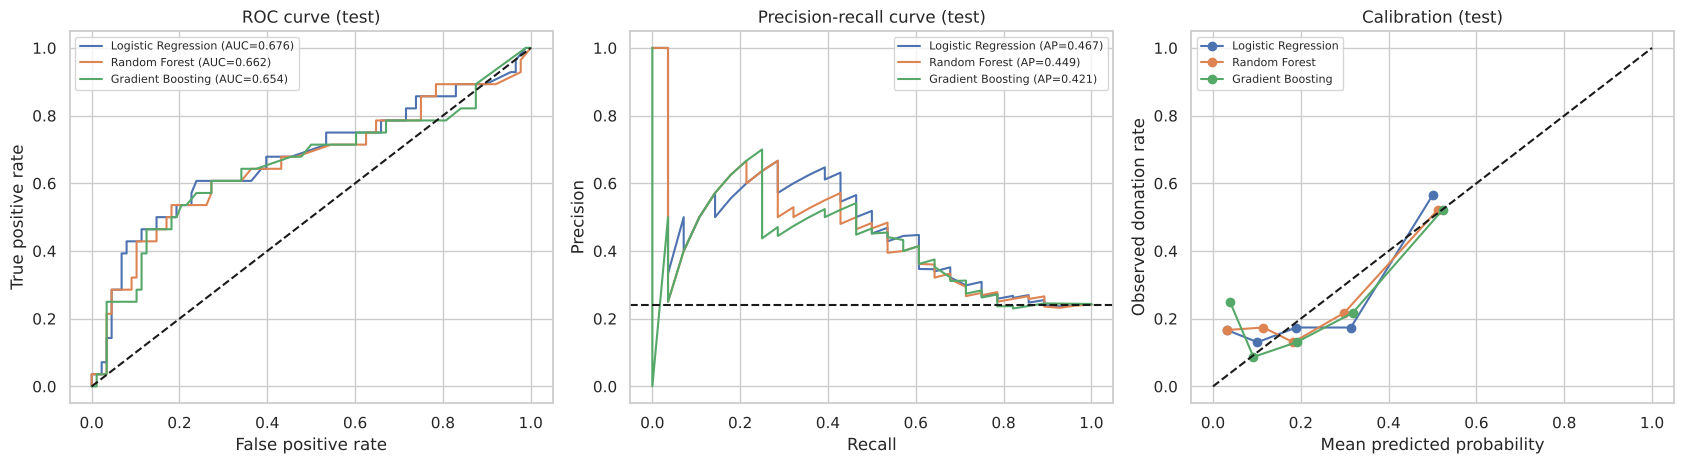

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for name in tuned:
    fpr, tpr, _ = roc_curve(y_test, test_probs[name])
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, test_probs[name]):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, test_probs[name])
    axes[1].plot(rc, pr, label=f"{name} (AP={average_precision_score(y_test, test_probs[name]):.3f})")
    fp, mp = calibration_curve(y_test, test_probs[name], n_bins=5, strategy="quantile")
    axes[2].plot(mp, fp, marker="o", label=name)
axes[0].plot([0, 1], [0, 1], "k--"); axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curve (test)")
axes[1].axhline(y_test.mean(), color="k", ls="--"); axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall curve (test)")
axes[2].plot([0, 1], [0, 1], "k--"); axes[2].set(xlabel="Mean predicted probability", ylabel="Observed donation rate", title="Calibration (test)")
for a in axes: a.legend(fontsize=8)
plt.tight_layout(); plt.show()

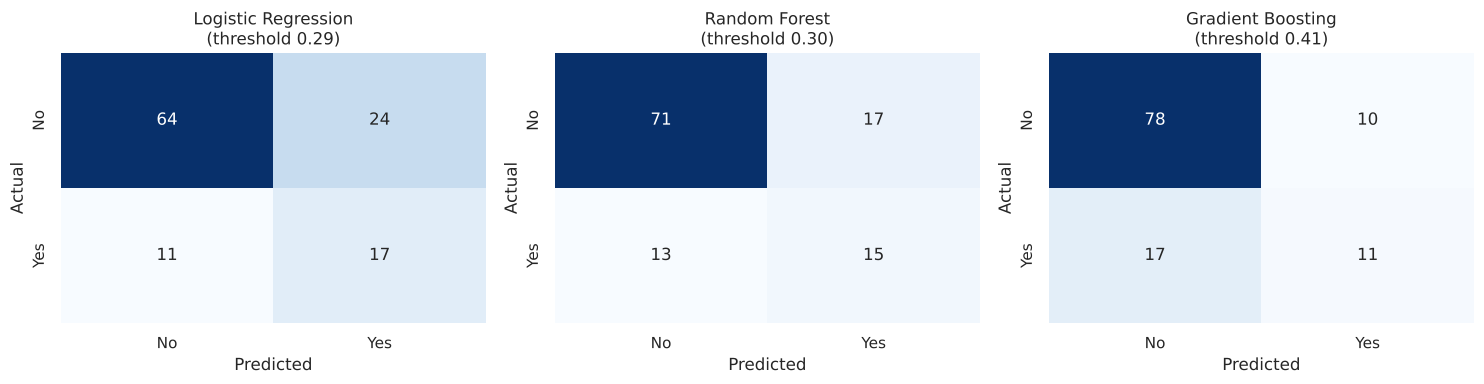

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, name in zip(axes, tuned):
    cm = confusion_matrix(y_test, (test_probs[name] >= thresholds[name]).astype(int))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["No", "Yes"], yticklabels=["No", "Yes"])
    ax.set(title=f"{name}\n(threshold {thresholds[name]:.2f})", xlabel="Predicted", ylabel="Actual")
plt.tight_layout(); plt.show()

## 2.7 Because the test set is small — how much can we trust the ranking?

116 test donors (about 28 positives) is a small sample, so a single test AUC can swing by several points. A bootstrap of the test set gives a rough 95% interval for each model's AUC and shows whether the models can really be told apart.

In [27]:
rng = np.random.default_rng(SEED)
y_arr = y_test.to_numpy()
boot = {n: [] for n in tuned}
for _ in range(1000):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    if y_arr[idx].min() == y_arr[idx].max():
        continue
    for n in tuned:
        boot[n].append(roc_auc_score(y_arr[idx], test_probs[n][idx]))

pd.DataFrame({n: {"AUC (point)": roc_auc_score(y_test, test_probs[n]),
                  "2.5%": np.percentile(v, 2.5), "97.5%": np.percentile(v, 97.5)} for n, v in boot.items()}).T.round(3)

,AUC (point),2.5%,97.5%
Logistic Regression,0.676,0.543,0.807
Random Forest,0.662,0.527,0.799
Gradient Boosting,0.654,0.520,0.791


### Is the lower test score a bad draw or a real problem?

The cross-validated AUC on the training data (~0.77) is noticeably higher than the AUC on this particular test split. To see whether the test split is simply an unlucky sample, the tuned models are scored with repeated cross-validation over **all 576 donors** (a more stable estimate; slightly optimistic because the hyper-parameters were tuned on the training part).

In [28]:
full_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED + 1)
rows = []
for name, pipe in tuned.items():
    r = cross_validate(pipe, X, y, cv=full_cv, scoring={"auc": "roc_auc", "ll": "neg_log_loss"}, n_jobs=-1)
    a = r["test_auc"]
    rows.append({"model": name, "mean AUC (all data)": a.mean(), "std across folds": a.std(),
                 "min fold": a.min(), "max fold": a.max(), "log loss": -r["test_ll"].mean()})
pd.DataFrame(rows).set_index("model").round(3)

,mean AUC (all data),std across folds,min fold,max fold,log loss
model,,,,,
Logistic Regression,0.754,0.052,0.638,0.828,0.478
Random Forest,0.736,0.053,0.625,0.832,0.482
Gradient Boosting,0.731,0.056,0.587,0.828,0.491


## 2.8 What drives the predictions?

Standardised logistic-regression coefficients (log-odds per 1 SD):
recency         -0.677
time            -0.358
tenure_gap      -0.141
frequency       -0.113
log_recency     -0.071
donation_rate    0.142
log_frequency    0.985


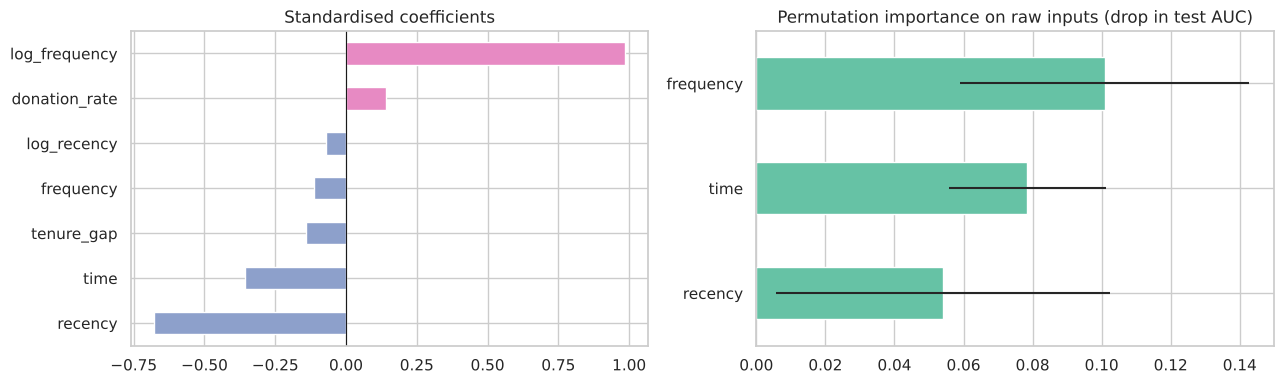

In [29]:
final_name = "Logistic Regression"
final_model = tuned[final_name]

coefs = pd.Series(final_model.named_steps["model"].coef_[0],
                  index=add_features(X_train).columns).sort_values()
print("Standardised logistic-regression coefficients (log-odds per 1 SD):")
print(coefs.round(3).to_string())

perm = permutation_importance(final_model, X_test, y_test, scoring="roc_auc", n_repeats=50, random_state=SEED)
imp = pd.Series(perm.importances_mean, index=RAW_FEATURES).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
coefs.plot.barh(ax=axes[0], color=["#8da0cb" if v < 0 else "#e78ac3" for v in coefs]); axes[0].set_title("Standardised coefficients"); axes[0].axvline(0, color="k", lw=.8)
imp.plot.barh(ax=axes[1], xerr=pd.Series(perm.importances_std, index=RAW_FEATURES)[imp.index], color="#66c2a5"); axes[1].set_title("Permutation importance on raw inputs (drop in test AUC)")
plt.tight_layout(); plt.show()

## 2.9 Saving the model for production

In [30]:
import joblib

# Refit the chosen pipeline on ALL labelled data (train + test) before deployment
from sklearn.base import clone
production_model = clone(final_model).fit(X, y)
production_threshold = thresholds[final_name]

joblib.dump({"model": production_model, "threshold": production_threshold,
             "features": RAW_FEATURES}, "blood_donation_model.joblib")

def predict_donor(recency, frequency, time, bundle_path="blood_donation_model.joblib"):
    """Return P(donor gives blood next drive) and a yes/no flag for one donor."""
    b = joblib.load(bundle_path)
    row = pd.DataFrame([[recency, frequency, time]], columns=b["features"])
    p = float(b["model"].predict_proba(row)[0, 1])
    return {"probability": round(p, 3), "likely_to_donate": bool(p >= b["threshold"])}

print("Recent, frequent donor :", predict_donor(recency=2, frequency=15, time=40))
print("Lapsed one-time donor  :", predict_donor(recency=35, frequency=1, time=35))

Recent, frequent donor : {'probability': 0.66, 'likely_to_donate': True}
Lapsed one-time donor  : {'probability': 0.014, 'likely_to_donate': False}


---
# 3. Model Comparison Report

## 3.1 Approach
* 9 algorithms + a dummy baseline were compared using **5-fold stratified CV repeated 3×** on the training split (460 donors).
* The three strongest families were tuned with `GridSearchCV` (optimising log loss), their decision thresholds were chosen from out-of-fold predictions, and they were scored **once** on a held-out test set (116 donors).
* Robustness was checked with a test-set bootstrap and with repeated CV on all 576 donors.

## 3.2 Results at a glance

| Model | CV ROC-AUC (train) | CV log loss | Test ROC-AUC | Test PR-AUC | Test log loss | All-data CV ROC-AUC |
|---|---|---|---|---|---|---|
| Dummy (prior) | 0.500 | 0.550 | 0.500 | 0.241 | 0.553 | – |
| **Logistic Regression (tuned, C=0.3)** | **0.769** | **0.463** | **0.676** | **0.467** | **0.546** | **0.754** |
| Random Forest (tuned) | 0.748 | 0.475 | 0.662 | 0.449 | 0.556 | 0.736 |
| Gradient Boosting (tuned) | 0.752 | 0.477 | 0.654 | 0.421 | 0.561 | 0.731 |

Other untuned models (CV ROC-AUC): Naive Bayes 0.759, AdaBoost 0.743, KNN 0.741, Decision Tree 0.719, SVM-RBF 0.710. Full tables are printed in Section 2.

## 3.3 What the comparison shows
1. **Every model beats the dummy baseline** on ROC-AUC, so recency / frequency / time clearly carry real signal about who returns.
2. **The simplest strong model wins or ties everywhere.** Regularised logistic regression has the best CV ROC-AUC, the best (lowest) log loss, the best test PR-AUC and the best all-data CV score, and it also has the smallest fold-to-fold variation. The more flexible models (Random Forest, Gradient Boosting, SVM, KNN) do not extract more signal — with ~460 rows and 3 base inputs there is little non-linear structure for them to find, and they pay for it in variance.
3. **Engineered features help the linear model modestly** (CV AUC 0.762 → 0.769, log loss 0.482 → 0.463), because `log_frequency` and the ratio features straighten out the skewed relationships. They do nothing for the tree models, which already handle skew and interactions on their own.
4. **Differences between the top models are small relative to the noise.** The bootstrap 95% intervals for test AUC overlap almost completely (roughly 0.52–0.81 for all three), and fold-to-fold AUC varies by ±0.05. The data support "logistic regression is at least as good as anything else we tried", **not** "logistic regression is dramatically better".
5. **Accuracy is not informative here.** All tuned models land near 70–77% test accuracy against a 76% do-nothing baseline; the gain is in ranking donors and in recall/precision at the chosen threshold (the logistic model at threshold 0.29 recovers about 61% of true donors with ~42% precision, versus 0% for the baseline).
6. **Naive Bayes** has competitive AUC but poor log loss (0.75 in CV), meaning its probabilities are badly over-confident — unsuitable if the probabilities will be used to prioritise donors.

## 3.4 An honest caveat about the test score
The held-out test AUC (0.676) is noticeably lower than the CV estimates (0.75–0.77). With only about 28 positive donors in the test set, a single split is very noisy: the bootstrap interval spans 0.54–0.81, and individual CV folds on all the data range from 0.64 to 0.83 for logistic regression. The more stable all-data estimate (**≈ 0.75 AUC**) is the better guide to expected performance. Realistically, this model should be described as a **moderate** predictor: useful for ranking and prioritising donors, not for making confident individual predictions.

## 3.5 Recommendation for production: **Logistic Regression** (C = 0.3, 7 engineered features, standardised)

| Reason | Detail |
|---|---|
| Best or tied-best performance | Top CV ROC-AUC and log loss; best test PR-AUC; no complex model beats it |
| Good probabilities | Lowest log loss and Brier score among the tuned candidates, so the output can be read as "chance this donor returns" and used to rank outreach |
| Stability | Lowest variance across folds; unlikely to swing when retrained on new data |
| Interpretability | Coefficients are readable: more recent and more frequent donors → higher probability (recency effect is non-linear in the raw data, see Section 1.7) (`log_frequency` is the strongest positive driver, `recency` the strongest negative). Easy to explain to non-technical staff |
| Cost | Microseconds per prediction, a tiny model file, no special infrastructure |
| Simple inputs | Needs only three raw numbers the centre already records; feature engineering is inside the saved pipeline |

**Operating threshold.** 0.29 maximises out-of-fold F1 (recall ≈ 0.6, precision ≈ 0.4). The centre should treat the threshold as a business dial: raise it to contact fewer, more-certain donors; lower it to reach more potential donors at the cost of more wasted contacts.

**Before / after deployment**
* The saved bundle (`blood_donation_model.joblib` + `donor_features.py`) is refit on all 576 labelled donors.
* Monitor the real return rate against predicted probabilities (calibration) every drive and retrain periodically; donor behaviour shifts with the academic calendar.
* This data is one snapshot from one campus drive. Performance on other campuses or years is untested, and richer features (age, donor type, drive date, reminders sent) would likely improve results more than a more complex algorithm.

---
# 4. Report on Challenges Faced

| # | Challenge | Evidence in the data | Technique used | Why this technique |
|---|---|---|---|---|
| 1 | **Perfectly redundant feature** | `volume_cc == 250 × frequency` in all 576 rows; VIF = ∞ | Dropped `volume_cc` (checked with an explicit consistency test and VIF) | It carries zero extra information and makes linear-model coefficients unstable. Removing it loses nothing |
| 2 | **Class imbalance** | Only 24% positives; a "never donates" model scores 76% accuracy | Stratified train/test split and stratified repeated CV; metrics: ROC-AUC, PR-AUC, log loss, F1/recall; threshold tuning; dummy baseline for reference | Stratification keeps the 24% rate in every fold. Accuracy would reward the useless majority-class model, so threshold-free and probability metrics lead the comparison. Resampling (SMOTE / oversampling) was *not* used: with ~140 positives, synthetic points mostly add noise, and it distorts the probabilities that the centre wants to use |
| 3 | **Very small dataset** | 576 rows (460 for training, 116 for test) | Repeated stratified 5-fold CV (3–5 repeats), small tuning grids, shallow trees, regularisation, bootstrap CIs | A single split is very noisy at this size. Repetition reduces the variance of the estimates; small grids and regularisation avoid over-fitting the folds |
| 4 | **Skewed features and high values** | `frequency` skew 3.5, 31 IQR-flagged values; `recency` skew 2.1 | Kept the outliers; added `log1p` features; used scale-insensitive models alongside scaled linear/distance models | The extreme values are real loyal donors — the group most likely to return — so deleting them would remove signal. Log transforms stop them dominating the linear model |
| 5 | **Little signal per raw feature** | `time` shows no significant difference between donors and non-donors (p = 0.85) | Engineered `donation_rate`, `tenure_gap`, `log_frequency`, `log_recency`; ablation test (raw vs engineered) | Account age only matters relative to how often someone gave. The ablation showed a small but consistent gain for the linear model and no harm to others, so the features were kept |
| 6 | **Poor recall at default threshold** | Tuned logistic regression recall ≈ 0.27 at 0.5 (CV) | Chose the threshold from out-of-fold training predictions (maximising F1) rather than using 0.5 or tuning on the test set | At a 24% base rate the model rarely exceeds 50% confidence. Picking the threshold on training data avoids leaking the test set into the decision |
| 7 | **Model comparison being unreliable** | Fold AUC std ≈ 0.05; test bootstrap CI ≈ ±0.13 | Repeated CV on all data, bootstrap intervals, comparing log loss and calibration as well as AUC | Prevents over-claiming that one model is "best" on differences that are within noise; leads to preferring the simplest model that is not worse |
| 8 | **Optimistic or leaky evaluation** | Easy to tune on the test set or fit scalers on all data | Test set used once at the end; scaling and feature engineering placed inside a scikit-learn `Pipeline` so each CV fold fits them on its own training portion | Keeps all reported scores honest and guarantees the same preprocessing at training and prediction time |
| 9 | **Test score lower than CV score** | Test AUC 0.676 vs CV 0.77 | Reported both and investigated (bootstrap, all-data repeated CV) instead of selecting a split that looks better | Only about 28 positives are in the test set, so luck plays a large role. Being transparent about this gives the business a realistic expectation (≈ 0.75 AUC) |
| 10 | **Deployment mismatch** | A pickled pipeline that uses a notebook-defined function cannot be loaded elsewhere | Moved the feature code to `donor_features.py` and saved a bundle with the model, threshold and expected columns | Makes the model loadable in any other script or service |
| 11 | **Duplicate-looking rows** | 153 rows have identical feature values (different `donor_id`) | Kept them | They are different donors with the same profile; removing them would distort the true frequency of common profiles |

## Conclusion
Donor *recency* and *frequency* are the useful signals: people who gave within the last half-year and who have given often are much more likely to come back. A tuned, regularised **logistic regression** on these inputs is the recommended production model — it matches or beats more complex alternatives, produces the best-behaved probabilities, and is simple to explain and deploy. Expected performance is moderate (ROC-AUC ≈ 0.75), so it should be used to **rank and prioritise** donor outreach rather than as a certain predictor of individual behaviour.